# 02 — Uji hipotesis H1–H5

Di Fase 3, query SQL menjawab Q1–Q6 secara deskriptif. Notebook ini menguji apakah pola itu
cukup kuat secara statistik untuk memutuskan hipotesis H1–H5 dari Fase 1.

**Prinsip yang dipakai:**
- **Unit analisis yang kira-kira independen.** Harga harian saling berkorelasi kuat dari hari ke
  hari, jadi menguji jutaan baris harian akan menghasilkan p-value yang terlalu kecil. Yang diuji
  adalah provinsi, tahun, atau peristiwa Lebaran.
- **Uji non-parametrik** (Wilcoxon, Mann-Whitney, uji tanda), karena sebarannya miring dan
  jumlah unitnya kecil (5–34).
- **Ukuran efek selalu dilaporkan**, bukan hanya p-value. Hipotesis bisnis butuh "seberapa
  besar", bukan hanya "ada bedanya".
- Kalau ada banyak uji sekaligus, p-value dikoreksi dengan **Holm**.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

from src.db import query
from src.viz import (CMAP_DIV, INK_2, MUTED, SERIES, save, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore", "Mean of empty slice")
pd.set_option("display.float_format", "{:,.3f}".format)
rng = np.random.default_rng(42)


def bootstrap_ci(x, stat=np.median, n=5000, alpha=0.05):
    """Interval kepercayaan bootstrap persentil."""
    x = np.asarray(x)
    boot = [stat(rng.choice(x, len(x), replace=True)) for _ in range(n)]
    return np.quantile(boot, [alpha / 2, 1 - alpha / 2])

In [2]:
# Harga bulanan per provinsi, pasar tradisional, dengan harga nasional varian yang sama
bulanan = query("""
    SELECT b.bulan, w.nama_wilayah, w.pulau, k.kategori, k.nama_varian, b.harga_rata,
           n.harga_rata AS harga_nasional
    FROM mart.fact_harga_bulanan AS b
    JOIN mart.fact_harga_bulanan AS n
      ON n.bulan = b.bulan AND n.komoditas_id = b.komoditas_id
     AND n.jenis_pasar_id = b.jenis_pasar_id AND n.wilayah_id = 0
    JOIN mart.dim_wilayah AS w ON w.wilayah_id = b.wilayah_id
    JOIN mart.dim_komoditas AS k ON k.komoditas_id = b.komoditas_id
    WHERE b.jenis_pasar_id = 1 AND NOT w.is_nasional
""")
bulanan["bulan"] = pd.to_datetime(bulanan["bulan"])
bulanan["tahun"] = bulanan.bulan.dt.year
print(f"{len(bulanan):,} baris; {bulanan.nama_wilayah.nunique()} provinsi; {bulanan.nama_varian.nunique()} varian")

73,442 baris; 34 provinsi; 21 varian


## H1. Cabai & bawang merah paling volatil; beras & gula paling stabil

**Ukuran:** ayunan harga tahunan = harga bulan termahal ÷ bulan termurah − 1, per provinsi ×
varian × tahun (2018–2025, tahun penuh). Lalu dirata-ratakan per provinsi dan kategori.

**Uji:** Wilcoxon signed-rank berpasangan per provinsi (n = 34): apakah ayunan kelompok
"cabai & bawang merah" lebih besar dari "beras & gula" di provinsi yang sama?

In [3]:
penuh = bulanan[bulanan.tahun.between(2018, 2025)]
ayunan = (penuh.groupby(["nama_wilayah", "kategori", "nama_varian", "tahun"]).harga_rata
          .agg(lambda s: s.max() / s.min() - 1).rename("ayunan").reset_index())
ayunan_kat = ayunan.groupby(["nama_wilayah", "kategori"]).ayunan.mean().unstack()

VOLATIL = ["Cabai Merah", "Cabai Rawit", "Bawang Merah"]
STABIL = ["Beras", "Gula Pasir"]
h1 = pd.DataFrame({
    "cabai_bawang": ayunan_kat[VOLATIL].mean(axis=1),
    "beras_gula": ayunan_kat[STABIL].mean(axis=1),
})
w = stats.wilcoxon(h1.cabai_bawang, h1.beras_gula, alternative="greater")
rasio = h1.cabai_bawang / h1.beras_gula
print(f"Provinsi dengan ayunan cabai & bawang > beras & gula: {(rasio > 1).sum()} dari {len(h1)}")
print(f"Median ayunan cabai & bawang : {h1.cabai_bawang.median():.1%}")
print(f"Median ayunan beras & gula   : {h1.beras_gula.median():.1%}")
print(f"Median rasio per provinsi    : {rasio.median():.1f}x  (95% CI {bootstrap_ci(rasio).round(1)})")
print(f"Wilcoxon signed-rank (satu sisi): W = {w.statistic:.0f}, p = {w.pvalue:.1e}")

Provinsi dengan ayunan cabai & bawang > beras & gula: 34 dari 34
Median ayunan cabai & bawang : 113.1%
Median ayunan beras & gula   : 9.3%
Median rasio per provinsi    : 11.0x  (95% CI [10.1 13.7])
Wilcoxon signed-rank (satu sisi): W = 595, p = 5.8e-11


Apakah beras & gula benar-benar **paling** stabil? Urutkan semua kategori berdasarkan median
ayunan per provinsi, lalu uji perbedaan antarkategori dengan Friedman (setiap provinsi menilai
semua kategori, jadi datanya berpasangan).

Friedman: chi2 = 295.4, p = 2.4e-58 (34 provinsi lengkap)


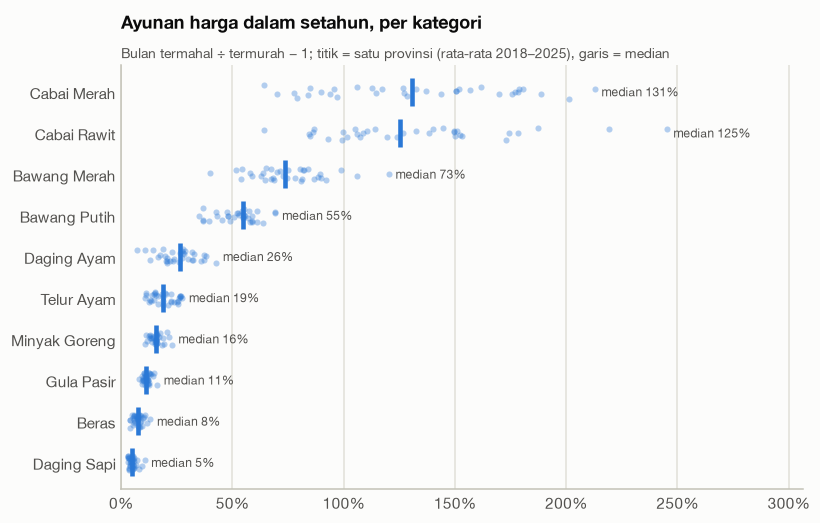

,median_ayunan
kategori,
Daging Sapi,0.047
Beras,0.075
Gula Pasir,0.114
Minyak Goreng,0.156
Telur Ayam,0.190
Daging Ayam,0.263
Bawang Putih,0.546
Bawang Merah,0.735
Cabai Rawit,1.253


In [4]:
urut_kat = ayunan_kat.median().sort_values()
lengkap = ayunan_kat.dropna()
fr = stats.friedmanchisquare(*[lengkap[c] for c in lengkap.columns])
print(f"Friedman: chi2 = {fr.statistic:.1f}, p = {fr.pvalue:.1e} ({len(lengkap)} provinsi lengkap)")

fig, ax = plt.subplots(figsize=(8, 5))
for i, kat in enumerate(urut_kat.index):
    x = ayunan_kat[kat].dropna()
    jitter = rng.uniform(-0.18, 0.18, len(x))
    ax.plot(x, i + jitter, "o", color=SERIES[0], alpha=0.35, markersize=4, markeredgecolor="none")
    ax.plot(x.median(), i, "|", color=SERIES[0], markersize=18, markeredgewidth=3)
    ax.text(x.max() + 0.03, i, f"median {x.median():.0%}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(range(len(urut_kat)), urut_kat.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, ayunan_kat.max().max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Ayunan harga dalam setahun, per kategori", pad=24)
subtitle(ax, "Bulan termahal ÷ termurah − 1; titik = satu provinsi (rata-rata 2018–2025), garis = median")
save(fig, "02_h1_ayunan_per_kategori")
plt.show()

urut_kat.rename("median_ayunan").to_frame()

**Keputusan H1: ✅ diterima, dengan koreksi.**
- Di **34 dari 34 provinsi**, ayunan harga cabai & bawang merah lebih besar daripada beras & gula.
  Median 113% vs 9%, atau **11 kali lipat** (95% CI 10–14×; Wilcoxon p = 6×10⁻¹¹).
- Urutan kategori dari yang paling bergejolak: cabai merah (131%), cabai rawit (125%), bawang
  merah (73%), bawang putih (55%), daging ayam (26%), telur (19%), minyak goreng (16%), gula
  (11%), beras (8%), daging sapi (5%).
- Koreksi: yang **paling stabil adalah daging sapi**, bukan beras dan gula. Beras dan gula ada
  di urutan kedua dan ketiga.

## H2. Indonesia Timur (Maluku, Papua, NTT) konsisten lebih mahal

**Ukuran:** indeks disparitas = harga provinsi ÷ harga nasional varian yang sama − 1,
dirata-ratakan per provinsi per tahun.

**Uji:**
1. Uji tanda per provinsi: dari 9 tahun (2018–2026), berapa tahun harganya di atas nasional?
   "Konsisten" = di atas nasional di semua atau hampir semua tahun.
2. Mann-Whitney: apakah 5 provinsi timur lebih mahal dari 29 provinsi lain?

In [5]:
TIMUR = ["Maluku", "Maluku Utara", "Papua", "Papua Barat", "Nusa Tenggara Timur"]
bulanan["disparitas"] = bulanan.harga_rata / bulanan.harga_nasional - 1
disp = (bulanan.groupby(["nama_wilayah", "tahun", "bulan"]).disparitas.mean()
        .groupby(["nama_wilayah", "tahun"]).mean().unstack())
disp = disp.loc[disp.mean(axis=1).sort_values(ascending=False).index]

h2 = pd.DataFrame({
    "rata_2018_2026": disp.mean(axis=1),
    "tahun_di_atas_nasional": (disp > 0).sum(axis=1),
    "n_tahun": disp.notna().sum(axis=1),
})
h2["p_uji_tanda"] = [stats.binomtest(k, n, 0.5, alternative="greater").pvalue
                     for k, n in zip(h2.tahun_di_atas_nasional, h2.n_tahun)]
h2["peringkat_termahal"] = h2.rata_2018_2026.rank(ascending=False).astype(int)
display(h2.loc[TIMUR])

mw = stats.mannwhitneyu(h2.loc[TIMUR, "rata_2018_2026"], h2.drop(TIMUR).rata_2018_2026, alternative="greater")
print(f"Mann-Whitney timur vs lainnya: U = {mw.statistic:.0f}, p = {mw.pvalue:.3f}")
tanpa_ntt = [p for p in TIMUR if p != "Nusa Tenggara Timur"]
mw2 = stats.mannwhitneyu(h2.loc[tanpa_ntt, "rata_2018_2026"], h2.drop(TIMUR).rata_2018_2026, alternative="greater")
print(f"Mann-Whitney Maluku & Papua (tanpa NTT) vs lainnya: U = {mw2.statistic:.0f}, p = {mw2.pvalue:.4f}")
print("\nProvinsi lain yang di atas nasional di semua tahun:")
print(h2[(h2.tahun_di_atas_nasional == h2.n_tahun) & ~h2.index.isin(TIMUR)].index.tolist())

,rata_2018_2026,tahun_di_atas_nasional,n_tahun,p_uji_tanda,peringkat_termahal
nama_wilayah,,,,,
Maluku,0.117,9,9,0.002,6
Maluku Utara,0.200,9,9,0.002,1
Papua,0.195,9,9,0.002,2
Papua Barat,0.149,9,9,0.002,4
Nusa Tenggara Timur,0.030,8,9,0.020,13


Mann-Whitney timur vs lainnya: U = 134, p = 0.001
Mann-Whitney Maluku & Papua (tanpa NTT) vs lainnya: U = 113, p = 0.0002

Provinsi lain yang di atas nasional di semua tahun:
['Kalimantan Utara', 'Kalimantan Tengah', 'DKI Jakarta', 'Kalimantan Barat', 'Gorontalo', 'Kalimantan Timur', 'Sumatera Barat']


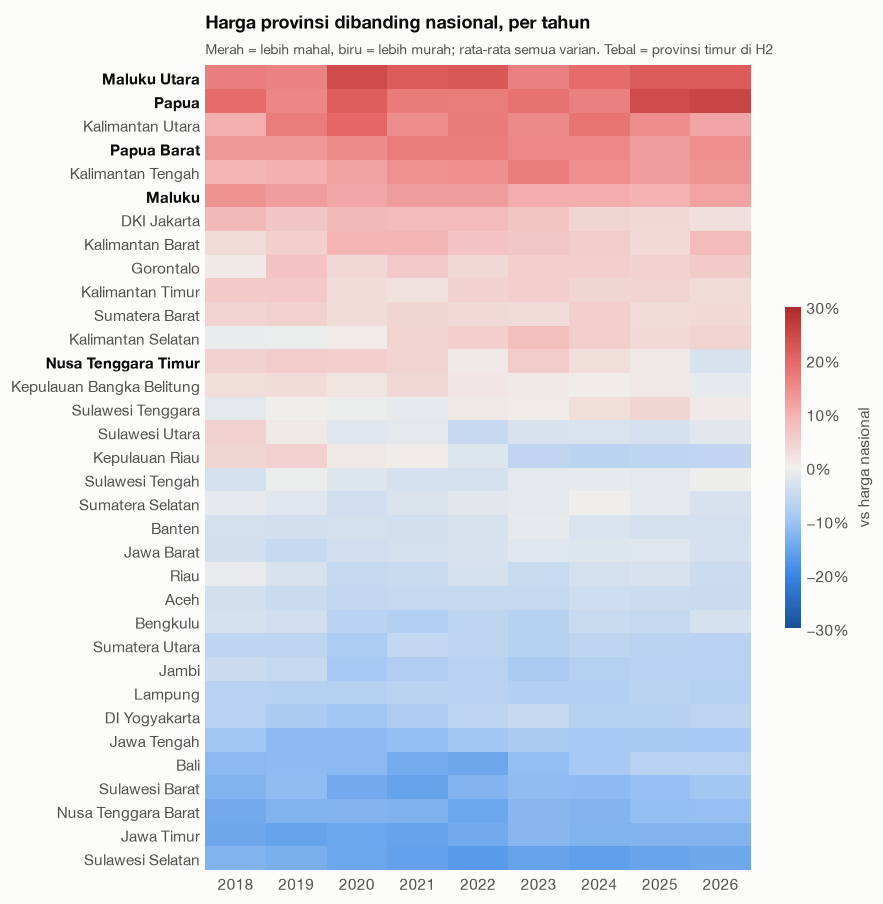

In [6]:
fig, ax = plt.subplots(figsize=(8, 9.5))
im = ax.imshow(disp, cmap=CMAP_DIV, vmin=-0.3, vmax=0.3, aspect="auto")
ax.set_xticks(range(disp.shape[1]), disp.columns)
ax.set_yticks(range(disp.shape[0]), disp.index)
for label in ax.get_yticklabels():
    if label.get_text() in TIMUR:
        label.set_fontweight("bold")
        label.set_color("#0b0b0b")
ax.grid(False)
ax.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.4, format=mtick.PercentFormatter(1, decimals=0))
cb.outline.set_visible(False)
cb.set_label("vs harga nasional", color=INK_2)
ax.set_title("Harga provinsi dibanding nasional, per tahun", pad=24)
subtitle(ax, "Merah = lebih mahal, biru = lebih murah; rata-rata semua varian. Tebal = provinsi timur di H2")
save(fig, "02_h2_disparitas_per_tahun")
plt.show()

**Keputusan H2: ⚠️ sebagian.**
- **Maluku, Maluku Utara, Papua, dan Papua Barat** lebih mahal dari nasional di **9 dari 9 tahun**
  (uji tanda p = 0,002 untuk masing-masing), rata-rata +12% s.d. +20%. Keempatnya masuk 6
  provinsi termahal.
- **NTT tidak cocok dengan hipotesis**: rata-rata hanya +3% (peringkat 13), dan di 2026 sudah
  di bawah harga nasional.
- Bukan hanya timur: **Kalimantan** (Utara, Tengah, Barat, Timur), DKI Jakarta, Gorontalo, dan
  Sumatera Barat juga di atas nasional di semua tahun.
- Jadi kelompok "selalu mahal" yang tepat adalah **Maluku, Papua, dan Kalimantan**. Termurah
  juga konsisten: Sulawesi Selatan, Jawa Timur, NTB, Sulawesi Barat.

## H3. Selisih produsen → pasar terbesar di komoditas yang mudah rusak

**Ukuran:** selisih = harga pasar tradisional ÷ harga produsen − 1, rata-rata 12 bulan terakhir
(Nov 2025 – Okt 2026), per provinsi × varian yang punya data di kedua jenis pasar.

**Kelompok:**
- mudah rusak: cabai (4 varian) dan bawang merah
- tahan simpan: beras (6), gula (2), minyak goreng (3)
- bawang putih tidak dipakai (data produsen hanya 2 provinsi); daging dan telur dilaporkan
  terpisah karena tidak masuk dua kelompok di atas.

**Uji:** Wilcoxon signed-rank berpasangan per provinsi.

In [7]:
rantai = query("""
    SELECT w.nama_wilayah, k.kategori, k.nama_varian,
           avg(p.harga_rata / prod.harga_rata - 1) AS selisih
    FROM mart.fact_harga_bulanan AS p
    JOIN mart.fact_harga_bulanan AS prod
      ON prod.bulan = p.bulan AND prod.wilayah_id = p.wilayah_id
     AND prod.komoditas_id = p.komoditas_id AND prod.jenis_pasar_id = 4
    JOIN mart.dim_wilayah AS w ON w.wilayah_id = p.wilayah_id
    JOIN mart.dim_komoditas AS k ON k.komoditas_id = p.komoditas_id
    WHERE p.jenis_pasar_id = 1 AND NOT w.is_nasional
      AND p.bulan BETWEEN '2025-11-01' AND '2026-10-01'
    GROUP BY w.nama_wilayah, k.kategori, k.nama_varian
""")
MUDAH_RUSAK = ["Cabai Merah", "Cabai Rawit", "Bawang Merah"]
TAHAN_SIMPAN = ["Beras", "Gula Pasir", "Minyak Goreng"]
rantai["kelompok"] = np.select(
    [rantai.kategori.isin(MUDAH_RUSAK), rantai.kategori.isin(TAHAN_SIMPAN), rantai.kategori == "Bawang Putih"],
    ["mudah rusak", "tahan simpan", "tidak dipakai"], "daging & telur")

h3 = rantai.groupby(["nama_wilayah", "kelompok"]).selisih.mean().unstack()
pasangan = h3[["mudah rusak", "tahan simpan"]].dropna()
w3 = stats.wilcoxon(pasangan["mudah rusak"], pasangan["tahan simpan"], alternative="greater")
beda = pasangan["mudah rusak"] - pasangan["tahan simpan"]
print(f"Provinsi dengan data kedua kelompok: {len(pasangan)}")
print(f"Median selisih mudah rusak : {pasangan['mudah rusak'].median():.1%}")
print(f"Median selisih tahan simpan: {pasangan['tahan simpan'].median():.1%}")
print(f"Median beda per provinsi   : {beda.median():.1%} poin (95% CI {np.round(bootstrap_ci(beda) * 100, 1)})")
print(f"Provinsi dengan selisih mudah rusak > tahan simpan: {(beda > 0).sum()} dari {len(beda)}")
print(f"Wilcoxon signed-rank (satu sisi): W = {w3.statistic:.0f}, p = {w3.pvalue:.1e}")

Provinsi dengan data kedua kelompok: 31
Median selisih mudah rusak : 55.7%
Median selisih tahan simpan: 14.1%
Median beda per provinsi   : 43.1% poin (95% CI [30.7 47.9])
Provinsi dengan selisih mudah rusak > tahan simpan: 28 dari 31
Wilcoxon signed-rank (satu sisi): W = 469, p = 5.9e-07


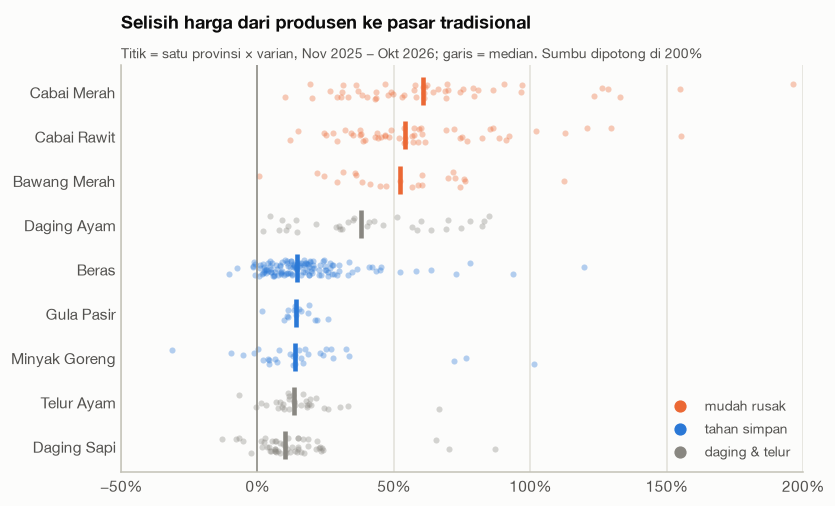

,kategori,kelompok,median,n
5,Daging Sapi,daging & telur,0.103,52
8,Telur Ayam,daging & telur,0.132,32
7,Minyak Goreng,tahan simpan,0.137,32
6,Gula Pasir,tahan simpan,0.141,16
1,Beras,tahan simpan,0.146,125
4,Daging Ayam,daging & telur,0.378,32
0,Bawang Merah,mudah rusak,0.522,23
3,Cabai Rawit,mudah rusak,0.542,52
2,Cabai Merah,mudah rusak,0.607,52


In [8]:
per_kat = rantai[rantai.kelompok != "tidak dipakai"].groupby(["kategori", "kelompok"]).selisih
ringkas3 = per_kat.median().rename("median").reset_index().assign(n=per_kat.size().values)
ringkas3 = ringkas3.sort_values("median")
warna_kelompok = {"mudah rusak": SERIES[1], "tahan simpan": SERIES[0], "daging & telur": MUTED}

fig, ax = plt.subplots(figsize=(8, 4.8))
for i, r in enumerate(ringkas3.itertuples()):
    x = rantai[(rantai.kategori == r.kategori)].selisih
    jitter = rng.uniform(-0.18, 0.18, len(x))
    ax.plot(x, i + jitter, "o", color=warna_kelompok[r.kelompok], alpha=0.35, markersize=4, markeredgecolor="none")
    ax.plot(r.median, i, "|", color=warna_kelompok[r.kelompok], markersize=18, markeredgewidth=3)
ax.set_yticks(range(len(ringkas3)), ringkas3.kategori)
for kel, c in warna_kelompok.items():
    ax.plot([], [], "o", color=c, label=kel, markersize=7)
ax.legend(loc="lower right")
ax.axvline(0, color=MUTED, linewidth=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(-0.5, 2.0)
ax.grid(axis="y", visible=False)
ax.set_title("Selisih harga dari produsen ke pasar tradisional", pad=24)
subtitle(ax, "Titik = satu provinsi × varian, Nov 2025 – Okt 2026; garis = median. Sumbu dipotong di 200%")
save(fig, "02_h3_selisih_rantai_pasok")
plt.show()
ringkas3

**Keputusan H3: ✅ diterima untuk cabai dan bawang merah, tidak untuk protein hewani.**
- Di **28 dari 31 provinsi**, selisih produsen → pasar untuk cabai & bawang merah lebih besar
  daripada beras, gula, dan minyak goreng. Median 56% vs 14%, beda **43 poin persen** (95% CI
  31–48; Wilcoxon p = 6×10⁻⁷).
- Daging ayam ada di tengah (38%). Telur (13%) dan daging sapi (10%) setara dengan komoditas
  tahan simpan, padahal keduanya juga mudah rusak. Jadi "mudah rusak" saja tidak menjelaskan
  selisih; kemungkinan rantai pasok protein hewani lebih pendek atau lebih terintegrasi.

## H4. Daging, ayam, dan telur naik signifikan menjelang Lebaran, mulai ~2 minggu sebelumnya

**Ukuran** (sama dengan Q4): lonjakan = rata-rata harga H-14..H-1 ÷ rata-rata H-90..H-61 − 1,
harga nasional harian, 9 Lebaran (2018–2026).

**Masalah:** harga cenderung naik pelan sepanjang tahun (inflasi). Kenaikan 2–4% dalam 2,5 bulan
bisa saja terjadi di periode mana pun, bukan karena Lebaran.

**Solusi — uji plasebo:** hitung statistik yang sama untuk *setiap* hari kerja yang jendelanya
tidak menyentuh Ramadan/Lebaran. Median plasebo di tahun yang sama = kenaikan "normal". Yang
diuji adalah **kelebihan** di atas kenaikan normal itu (Wilcoxon satu sisi, n = 9 Lebaran).

"Signifikan" butuh dua syarat: signifikan secara statistik (p < 0,05) **dan** cukup besar untuk
keputusan bisnis (kelebihan ≥ 5%).

In [9]:
harian = query("""
    SELECT f.tanggal, k.nama_varian, f.harga
    FROM mart.fact_harga_harian AS f
    JOIN mart.dim_komoditas AS k USING (komoditas_id)
    WHERE f.wilayah_id = 0 AND f.jenis_pasar_id = 1
""")
harian["tanggal"] = pd.to_datetime(harian["tanggal"])
harian = harian.pivot(index="tanggal", columns="nama_varian", values="harga").asfreq("D")

hari_besar = query("SELECT tanggal, nama_hari_besar FROM mart.dim_tanggal WHERE nama_hari_besar IS NOT NULL")
hari_besar["tanggal"] = pd.to_datetime(hari_besar["tanggal"])
lebaran = hari_besar[hari_besar.nama_hari_besar == "Idulfitri"].tanggal.sort_values().tolist()
natal = [t for t in hari_besar[hari_besar.nama_hari_besar == "Natal"].tanggal.sort_values()
         if t <= harian.index.max()]

# statistik untuk setiap tanggal acuan a: mean[a-14, a-1] / mean[a-90, a-61] - 1
r14 = harian.rolling("14D", min_periods=5).mean()
r30 = harian.rolling("30D", min_periods=10).mean()
lonjakan_semua = r14.shift(1, freq="D") / r30.shift(61, freq="D") - 1
lonjakan_semua = lonjakan_semua.reindex(harian.index)

# tanggal acuan plasebo: hari kerja yang jendelanya [a-90, a-1] tidak menyentuh [Lebaran-35, Lebaran+14]
acuan = lonjakan_semua.index[(lonjakan_semua.index.day_of_week < 5) & (lonjakan_semua.index >= "2018-04-01")]
dekat = np.zeros(len(acuan), dtype=bool)
for L in lebaran:
    dekat |= (acuan - pd.Timedelta(days=90) <= L + pd.Timedelta(days=14)) & (acuan >= L - pd.Timedelta(days=35))
plasebo = lonjakan_semua.loc[acuan[~dekat]]
print(f"Tanggal acuan plasebo: {len(plasebo):,}")


def uji_hari_besar(tanggal_list, varian, label):
    """Uji kelebihan lonjakan di atas kenaikan normal; koreksi Holm di dalam `varian`."""
    rows = []
    for var in varian:
        nilai = lonjakan_semua.loc[tanggal_list, var]
        normal = np.array([plasebo.loc[plasebo.index.year == t.year, var].median() for t in tanggal_list])
        kelebihan = (nilai.values - normal)
        kelebihan = kelebihan[~np.isnan(kelebihan)]
        p = stats.wilcoxon(kelebihan, alternative="greater").pvalue
        rows.append({"varian": var, "median_lonjakan": nilai.median(), "median_kenaikan_normal": np.median(normal),
                     "median_kelebihan": np.median(kelebihan), "naik_lebih_dari_normal": (kelebihan > 0).sum(),
                     "n": len(kelebihan), "p": p})
    hasil = pd.DataFrame(rows).set_index("varian")
    hasil["p_holm"] = multipletests(hasil.p, method="holm")[1]
    hasil["signifikan"] = hasil.p_holm < 0.05
    hasil["cukup_besar"] = hasil.median_kelebihan >= 0.05
    print(f"{label}: {len(tanggal_list)} kejadian, {len(varian)} varian (koreksi Holm di antara varian ini)")
    return hasil.sort_values("median_kelebihan", ascending=False)


H4_VARIAN = ["Daging Sapi Kualitas 1", "Daging Sapi Kualitas 2", "Daging Ayam Ras Segar", "Telur Ayam Ras Segar"]
h4 = uji_hari_besar(lebaran, H4_VARIAN, "Lebaran, varian H4")
h4

Tanggal acuan plasebo: 1,340
Lebaran, varian H4: 9 kejadian, 4 varian (koreksi Holm di antara varian ini)


,median_lonjakan,median_kenaikan_normal,median_kelebihan,naik_lebih_dari_normal,n,p,p_holm,signifikan,cukup_besar
varian,,,,,,,,,
Telur Ayam Ras Segar,0.018,-0.007,0.064,7,9,0.037,0.074,False,True
Daging Ayam Ras Segar,0.046,-0.006,0.056,7,9,0.049,0.074,False,True
Daging Sapi Kualitas 1,0.028,0.001,0.026,9,9,0.002,0.008,True,False
Daging Sapi Kualitas 2,0.029,-0.001,0.021,9,9,0.002,0.008,True,False


Sebagai konteks, varian lain di Lebaran yang sama (diuji sebagai keluarga terpisah):

In [10]:
h4_lain = uji_hari_besar(lebaran, [v for v in harian.columns if v not in H4_VARIAN], "Lebaran, varian lain")
h4_lain

Lebaran, varian lain: 9 kejadian, 17 varian (koreksi Holm di antara varian ini)


,median_lonjakan,median_kenaikan_normal,median_kelebihan,naik_lebih_dari_normal,n,p,p_holm,signifikan,cukup_besar
varian,,,,,,,,,
Cabai Rawit Merah,-0.081,0.029,0.110,5,9,0.715,1.000,False,True
Bawang Putih Ukuran Sedang,0.044,-0.012,0.052,6,9,0.285,1.000,False,True
Gula Pasir Lokal,0.026,0.002,0.025,7,9,0.010,0.156,False,False
Minyak Goreng Curah,0.005,0.005,0.008,6,9,0.285,1.000,False,False
Minyak Goreng Kemasan Bermerk 2,0.009,0.002,0.007,7,9,0.037,0.557,False,False
Gula Pasir Kualitas Premium,0.008,-0.001,0.007,8,9,0.004,0.066,False,False
Minyak Goreng Kemasan Bermerk 1,0.011,0.003,0.001,6,9,0.125,1.000,False,False
Beras Kualitas Bawah II,0.008,0.003,0.001,5,9,0.674,1.000,False,False
Beras Kualitas Super II,0.006,0.002,-0.001,4,9,0.455,1.000,False,False


Bagaimana kurvanya? Indeks harga harian terhadap baseline (H-90..H-61) untuk setiap Lebaran,
dirata-ratakan dari 9 Lebaran. Pita = interval kepercayaan 95% bootstrap (Lebaran diambil ulang).

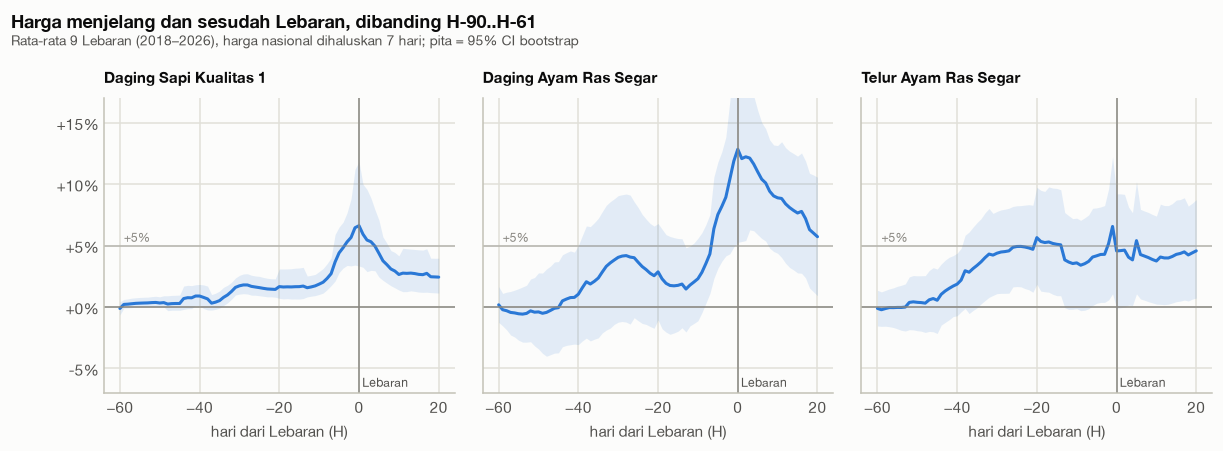

In [11]:
H = np.arange(-60, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, var in zip(axes, ["Daging Sapi Kualitas 1", "Daging Ayam Ras Segar", "Telur Ayam Ras Segar"]):
    kurva = []
    for L in lebaran:
        baseline = harian.loc[L - pd.Timedelta(days=90): L - pd.Timedelta(days=61), var].mean()
        halus = harian[var].rolling(7, center=True, min_periods=3).mean()   # rata-rata 7 hari
        kurva.append(halus.reindex([L + pd.Timedelta(days=int(h)) for h in H]).values / baseline)
    kurva = np.array(kurva)
    rata = np.nanmean(kurva, axis=0)
    rata[(~np.isnan(kurva)).sum(axis=0) < 6] = np.nan   # butuh data dari >= 6 Lebaran
    boot = np.array([np.nanmean(kurva[rng.integers(0, len(kurva), len(kurva))], axis=0) for _ in range(2000)])
    bawah, atas = np.nanquantile(boot, [0.025, 0.975], axis=0)
    ok = ~np.isnan(rata)
    ax.fill_between(H[ok], bawah[ok], atas[ok], color=SERIES[0], alpha=0.12, linewidth=0)
    ax.plot(H[ok], rata[ok], color=SERIES[0])
    ax.axhline(1, color=MUTED, linewidth=1)
    ax.axhline(1.05, color=MUTED, linewidth=1, linestyle=(0, (1, 0)), alpha=0.5)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.text(0.8, 0.935, "Lebaran", fontsize=8, color=INK_2)
    ax.text(-59, 1.053, "+5%", fontsize=8, color=MUTED)
    ax.set_title(var, fontsize=10)
    ax.set_xlabel("hari dari Lebaran (H)")
    ax.set_yticks([0.95, 1, 1.05, 1.1, 1.15])
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v - 1:+.0%}"))
axes[0].set_ylim(0.93, 1.17)
fig.suptitle("Harga menjelang dan sesudah Lebaran, dibanding H-90..H-61", x=0.06, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.06, 0.9, "Rata-rata 9 Lebaran (2018–2026), harga nasional dihaluskan 7 hari; pita = 95% CI bootstrap",
         color=INK_2, fontsize=9)
fig.subplots_adjust(top=0.78, wspace=0.08)
save(fig, "02_h4_kurva_lebaran")
plt.show()

Sebagai pembanding, uji yang sama untuk **Natal & Tahun Baru** (Nataru), dengan 25 Desember
sebagai hari-H (8 kejadian, 2018–2025).

In [12]:
nataru = uji_hari_besar(natal, list(harian.columns), "Nataru")
nataru.head(8)

Nataru: 8 kejadian, 21 varian (koreksi Holm di antara varian ini)


,median_lonjakan,median_kenaikan_normal,median_kelebihan,naik_lebih_dari_normal,n,p,p_holm,signifikan,cukup_besar
varian,,,,,,,,,
Cabai Rawit Merah,0.393,0.006,0.354,7,8,0.027,0.383,False,True
Cabai Rawit Hijau,0.237,-0.014,0.267,7,8,0.020,0.352,False,True
Bawang Merah Ukuran Sedang,0.297,0.071,0.234,8,8,0.004,0.082,False,True
Telur Ayam Ras Segar,0.104,-0.020,0.115,8,8,0.004,0.082,False,True
Cabai Merah Keriting,0.097,0.047,0.064,5,8,0.125,1.000,False,True
Cabai Merah Besar,0.149,0.040,0.060,5,8,0.125,1.000,False,True
Daging Ayam Ras Segar,0.057,-0.013,0.045,7,8,0.008,0.148,False,False
Minyak Goreng Curah,0.037,0.007,0.024,6,8,0.074,0.891,False,False


**Keputusan H4: ⚠️ sebagian. Arahnya benar, tapi kenaikannya kecil dan waktunya lebih telat.**
- **Daging sapi** naik lebih dari kenaikan normal di **9 dari 9 Lebaran** (p = 0,008 setelah
  koreksi Holm), tapi kelebihannya hanya **+2–3%**. Signifikan secara statistik, kecil secara bisnis.
- **Daging ayam (+5,6%) dan telur (+6,4%)** kelebihannya lebih besar, tapi hanya terjadi di 7 dari
  9 Lebaran, dan tidak signifikan setelah koreksi (p = 0,07).
- **Waktunya:** daging sapi dan ayam baru naik tajam sekitar **H-10** dan memuncak tepat di hari
  Lebaran (sapi ~+7%, ayam ~+13% dari baseline). Harga ayam masih +6% dua minggu setelah
  Lebaran. Telur naik pelan sepanjang Ramadan, sekitar +4–5%.
- Komoditas lain tidak naik secara berarti menjelang Lebaran; cabai cenderung turun.

**Temuan tambahan — Nataru justru lebih berisiko daripada Lebaran:**
- Menjelang Natal, median harga **cabai rawit merah naik 39%**, **bawang merah 30%** (naik di 8 dari 8
  tahun), **telur 10%** (8 dari 8 tahun), dan daging ayam 6% (7 dari 8 tahun).
- Dengan hanya 8 kejadian, tidak ada yang lolos koreksi 21 uji, jadi ini temuan eksploratif.
  Desember juga awal musim hujan (cabai termahal Jan–Mar, lihat Q5), jadi efek hari raya dan
  cuaca tidak bisa dipisahkan di data ini.
- **Rekomendasi:** untuk daging sapi dan ayam, amankan harga paling lambat ~H-14 Lebaran (sebelum
  kenaikan tajam di H-10). Risiko terbesar justru di akhir tahun: amankan stok bawang merah dan
  telur sebelum Desember, dan pakai kontrak harga cabai untuk Desember–Maret.

## H5. Pasar modern lebih mahal untuk komoditas segar, lebih murah untuk produk kemasan

**Ukuran:** selisih = harga pasar modern ÷ pasar tradisional − 1, rata-rata 12 bulan terakhir,
per provinsi × varian.

**Uji:** Wilcoxon signed-rank per varian (dua sisi, n = jumlah provinsi), lalu p-value dikoreksi
Holm untuk 21 uji. Hasilnya: lebih mahal / setara / lebih murah.

In [13]:
modern = query("""
    SELECT w.nama_wilayah, k.kategori, k.nama_varian,
           avg(m.harga_rata / t.harga_rata - 1) AS selisih
    FROM mart.fact_harga_bulanan AS m
    JOIN mart.fact_harga_bulanan AS t
      ON t.bulan = m.bulan AND t.wilayah_id = m.wilayah_id
     AND t.komoditas_id = m.komoditas_id AND t.jenis_pasar_id = 1
    JOIN mart.dim_wilayah AS w ON w.wilayah_id = m.wilayah_id
    JOIN mart.dim_komoditas AS k ON k.komoditas_id = m.komoditas_id
    WHERE m.jenis_pasar_id = 2 AND NOT w.is_nasional
      AND m.bulan BETWEEN '2025-11-01' AND '2026-10-01'
    GROUP BY w.nama_wilayah, k.kategori, k.nama_varian
""")
SEGAR = ["Cabai Merah", "Cabai Rawit", "Bawang Merah", "Bawang Putih", "Daging Sapi", "Daging Ayam", "Telur Ayam"]
rows = []
for (kat, var), g in modern.groupby(["kategori", "nama_varian"]):
    lo, hi = bootstrap_ci(g.selisih)
    rows.append({"varian": var, "kelompok": "segar" if kat in SEGAR else "pokok & kemasan",
                 "median": g.selisih.median(), "ci_bawah": lo, "ci_atas": hi, "n_provinsi": len(g),
                 "p": stats.wilcoxon(g.selisih).pvalue})
h5 = pd.DataFrame(rows).set_index("varian")
h5["p_holm"] = multipletests(h5.p, method="holm")[1]
h5["kesimpulan"] = np.where(h5.p_holm >= 0.05, "setara",
                            np.where(h5["median"] > 0, "modern lebih mahal", "modern lebih murah"))
h5 = h5.sort_values("median")
h5

,kelompok,median,ci_bawah,ci_atas,n_provinsi,p,p_holm,kesimpulan
varian,,,,,,,,
Gula Pasir Kualitas Premium,pokok & kemasan,-0.061,-0.079,-0.024,34,0.002,0.023,modern lebih murah
Gula Pasir Lokal,pokok & kemasan,-0.029,-0.037,-0.014,34,0.001,0.009,modern lebih murah
Minyak Goreng Curah,pokok & kemasan,0.000,-0.076,0.086,7,0.812,1.000,setara
Minyak Goreng Kemasan Bermerk 1,pokok & kemasan,0.004,-0.014,0.019,34,0.761,1.000,setara
Beras Kualitas Super II,pokok & kemasan,0.007,-0.019,0.032,31,0.622,1.000,setara
Beras Kualitas Medium I,pokok & kemasan,0.013,0.001,0.031,33,0.426,1.000,setara
Beras Kualitas Medium II,pokok & kemasan,0.016,-0.014,0.028,29,0.686,1.000,setara
Beras Kualitas Super I,pokok & kemasan,0.022,-0.044,0.039,31,0.900,1.000,setara
Beras Kualitas Bawah I,pokok & kemasan,0.031,-0.007,0.071,28,0.284,1.000,setara


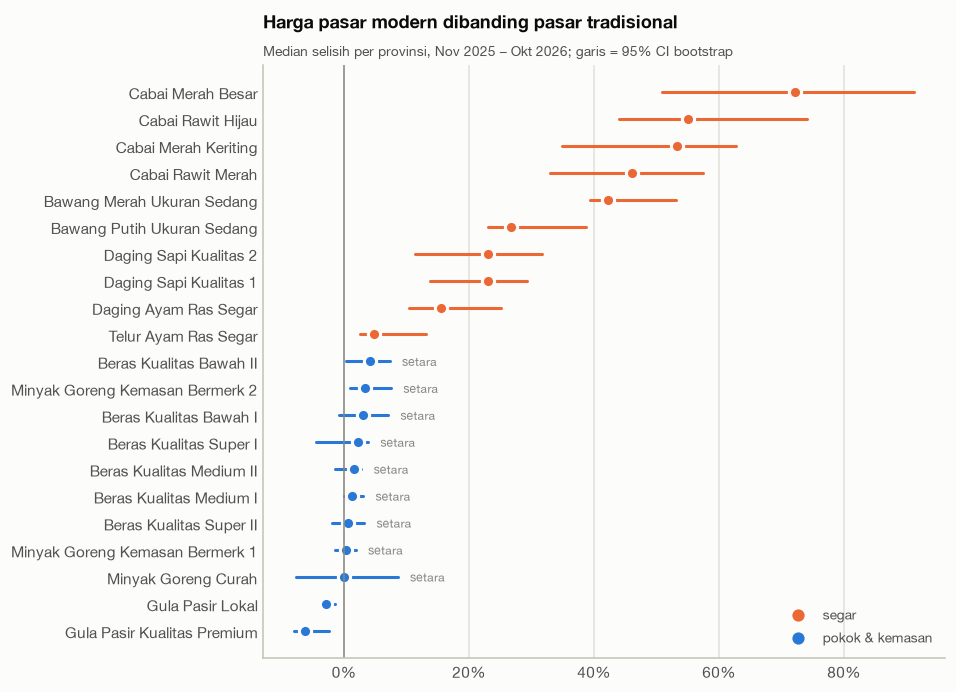

In [14]:
fig, ax = plt.subplots(figsize=(8, 7))
warna5 = {"segar": SERIES[1], "pokok & kemasan": SERIES[0]}
for i, r in enumerate(h5.itertuples()):
    c = warna5[r.kelompok]
    ax.plot([r.ci_bawah, r.ci_atas], [i, i], color=c, linewidth=2)
    ax.plot(r.median, i, "o", color=c, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
    if r.kesimpulan == "setara":
        ax.text(max(r.ci_atas, 0) + 0.02, i, "setara", va="center", fontsize=8, color=MUTED)
for kel, c in warna5.items():
    ax.plot([], [], "o", color=c, label=kel, markersize=7)
ax.legend(loc="lower right")
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(range(len(h5)), h5.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.set_title("Harga pasar modern dibanding pasar tradisional", pad=24)
subtitle(ax, "Median selisih per provinsi, Nov 2025 – Okt 2026; garis = 95% CI bootstrap")
save(fig, "02_h5_modern_vs_tradisional")
plt.show()

In [15]:
pd.crosstab(h5.kelompok, h5.kesimpulan)

kesimpulan,modern lebih mahal,modern lebih murah,setara
kelompok,,,
pokok & kemasan,0,2,9
segar,10,0,0


**Keputusan H5: ⚠️ sebagian.**
- **10 dari 10 varian segar lebih mahal di pasar modern**, semuanya signifikan setelah koreksi
  Holm: cabai +46% s.d. +72%, bawang +27% s.d. +42%, daging sapi +23%, ayam +16%, telur +5%.
- Untuk pokok & kemasan, **9 dari 11 varian setara** (median 0% s.d. +4%, tidak signifikan).
  Hanya **gula yang lebih murah** di pasar modern: premium −6%, lokal −3%.
- Jadi bagian pertama hipotesis sangat kuat, bagian kedua hanya berlaku untuk gula.

## Ringkasan keputusan hipotesis

| Hipotesis | Uji | Hasil | Keputusan |
|---|---|---|---|
| H1: cabai & bawang merah paling volatil, beras & gula paling stabil | Wilcoxon berpasangan, 34 provinsi | Ayunan 11× lebih besar di 34/34 provinsi (p < 0,001); paling stabil justru daging sapi | ✅ Diterima, dengan koreksi |
| H2: Indonesia Timur konsisten lebih mahal | Uji tanda per provinsi (9 tahun), Mann-Whitney | Maluku & Papua di atas nasional 9/9 tahun (p = 0,002); NTT hanya +3%; Kalimantan juga selalu mahal | ⚠️ Sebagian |
| H3: selisih produsen → pasar terbesar di komoditas mudah rusak | Wilcoxon berpasangan, 31 provinsi | Cabai & bawang merah 56% vs tahan simpan 14% (p < 0,001); tidak berlaku untuk telur & daging sapi | ✅ Diterima untuk cabai & bawang |
| H4: daging, ayam, telur naik signifikan ~2 minggu sebelum Lebaran | Wilcoxon vs plasebo, 9 Lebaran | Daging sapi naik 9/9 tapi hanya +2–3%; ayam & telur +6% tapi tidak konsisten; naik tajam baru ~H-10 | ⚠️ Sebagian |
| H5: modern lebih mahal untuk segar, lebih murah untuk kemasan | Wilcoxon per varian + Holm | Segar 10/10 lebih mahal; kemasan 9/11 setara, hanya gula lebih murah | ⚠️ Sebagian |

Lanjut ke [03_lead_lag_provinsi.ipynb](03_lead_lag_provinsi.ipynb).

## Ekspor untuk dashboard

Hasil uji Lebaran dan Nataru disimpan untuk grafik kalender risiko di Tableau.
Koreksi Holm tetap per keluarga uji, sama seperti di atas.

In [16]:
EXPORT_DIR = Path.cwd().parent / "data" / "exports"
komoditas = query("SELECT komoditas_id, nama_varian AS varian FROM mart.dim_komoditas")
risiko = pd.concat([
    h4.assign(hari_besar="Lebaran", keluarga_uji="Lebaran: varian H4"),
    h4_lain.assign(hari_besar="Lebaran", keluarga_uji="Lebaran: varian lain"),
    nataru.assign(hari_besar="Nataru", keluarga_uji="Nataru: semua varian"),
]).reset_index().merge(komoditas, on="varian")
risiko = (risiko[["hari_besar", "komoditas_id", "median_lonjakan", "median_kenaikan_normal", "median_kelebihan",
                  "naik_lebih_dari_normal", "n", "p_holm", "signifikan", "cukup_besar", "keluarga_uji"]]
          .rename(columns={"n": "n_kejadian"}).sort_values(["hari_besar", "komoditas_id"]))
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
risiko.to_csv(EXPORT_DIR / "risiko_hari_besar.csv", index=False, float_format="%.4f")
print(f"Tersimpan: data/exports/risiko_hari_besar.csv ({len(risiko)} baris)")
risiko.head()

Tersimpan: data/exports/risiko_hari_besar.csv (42 baris)


,hari_besar,komoditas_id,median_lonjakan,median_kenaikan_normal,median_kelebihan,naik_lebih_dari_normal,n_kejadian,p_holm,signifikan,cukup_besar,keluarga_uji
15,Lebaran,1,0.006,0.005,-0.006,4,9,1.000,False,False,Lebaran: varian lain
11,Lebaran,2,0.008,0.003,0.001,5,9,1.000,False,False,Lebaran: varian lain
13,Lebaran,3,0.006,-0.000,-0.003,4,9,1.000,False,False,Lebaran: varian lain
16,Lebaran,4,0.005,0.001,-0.008,3,9,1.000,False,False,Lebaran: varian lain
14,Lebaran,5,0.006,0.001,-0.004,4,9,1.000,False,False,Lebaran: varian lain
